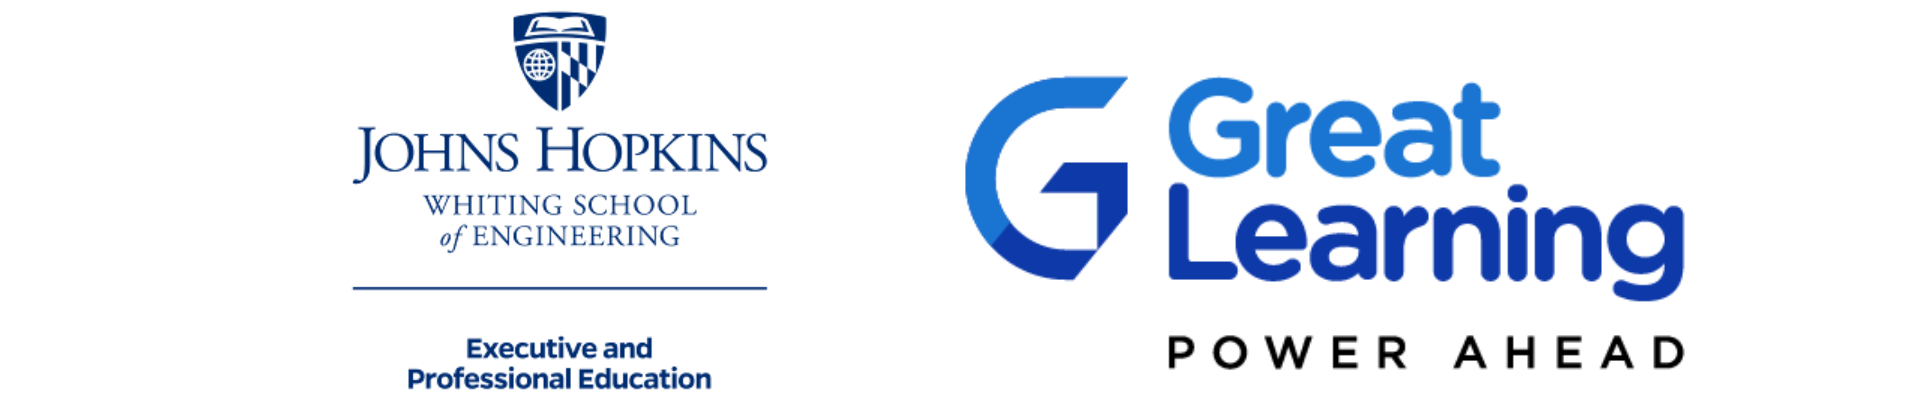


<center><font size=10>Core Concepts of Agentic AI Systems</font></center>


<center><font size=6>Competitive Analysis Automation with Agentic RAG</font></center>


## Learning Objectives

By the end of this notebook, you will be able to:

1. **Understand Agentic RAG** -- Implement a retrieve-then-grade pattern where the system decides at runtime whether internal knowledge is sufficient or a live web search is needed.
2. **Build a LangGraph State Machine** -- Model a multi-step agentic workflow as an explicit directed graph with typed state, conditional edges, and early-exit branches.
3. **Create and Query a Vector Knowledge Base** -- Chunk, embed, and store domain documents in ChromaDB; retrieve semantically relevant chunks for downstream tasks.
4. **Implement Retrieval Grading** -- Build a deterministic, logic-based grader that checks whether the retrieved context actually covers the target company, and understand the trade-offs versus using an LLM as the grader.
5. **Implement Conditional Routing / Self-Correction** -- Route graph execution to the internal KB path or fall back to live web search based on the grader's verdict, making the source-selection decision _agentic_.
6. **Compose Modular Business Tools** -- Wrap domain logic (validation, sector ID, competitor discovery, web scraping, report generation) as plain Python functions orchestrated by LangGraph nodes.


## Problem Statement


### Business Context

Strategy teams at large enterprises spend significant time manually gathering and synthesizing competitive intelligence. Analysts must search across internal research repositories, industry reports, and live news sources -- reconciling information from multiple, heterogeneous sources before they can produce a single actionable brief.

The challenge is that **internal knowledge bases** (analyst reports, positioning memos, pricing sheets) often contain richer, more curated intelligence than live web results -- but they go stale. A well-designed agentic system should _first_ try to answer from the internal KB, and only fall back to live web search when the KB does not have sufficient coverage. This runtime decision is the core of **Agentic RAG**.


### Objective

Build an end-to-end **Agentic RAG pipeline** that:

- Accepts a company name as input
- Validates the company, identifies its sector and top competitors
- **Retrieves** relevant strategy documents from an internal Competitive Intelligence knowledge base
- **Grades** the retrieval quality using a deterministic, logic-based coverage check
- **Routes** to the internal KB path if coverage is sufficient, or falls back to live web search if not
- Synthesizes a structured Competitive Analysis Report and reports which data source was used


### Solution Approach

The pipeline is implemented as a **LangGraph state machine** with the following stages:

| Stage | Node                   | Description                                                                       |
| ----- | ---------------------- | --------------------------------------------------------------------------------- |
| 1     | `validate_company`     | Web heuristics + LLM gate to confirm the company exists                           |
| 2     | `identify_sector`      | Multi-strategy web search + pattern matching to classify industry                 |
| 3     | `identify_competitors` | Competitor discovery via web search + ranked extraction                           |
| 4     | `retrieve_from_kb`     | Semantic search over internal ChromaDB knowledge base                             |
| 5     | `grade_retrieval`      | Deterministic coverage check: SUFFICIENT -> KB path, INSUFFICIENT -> web fallback |
| 6a    | `gather_strategy_data` | **Fallback only** -- live Tavily web search for each entity                       |
| 6b    | `generate_report`      | LLM synthesis of the Competitor Comparison Report                                 |

**The agentic element** is the conditional routing after grading: the graph decides _at runtime_ which data source to use. This is not hardcoded -- it depends on what the grader finds in the retrieved content.

> **Note:** All corpus documents used in this notebook are synthetic and fabricated for teaching purposes.


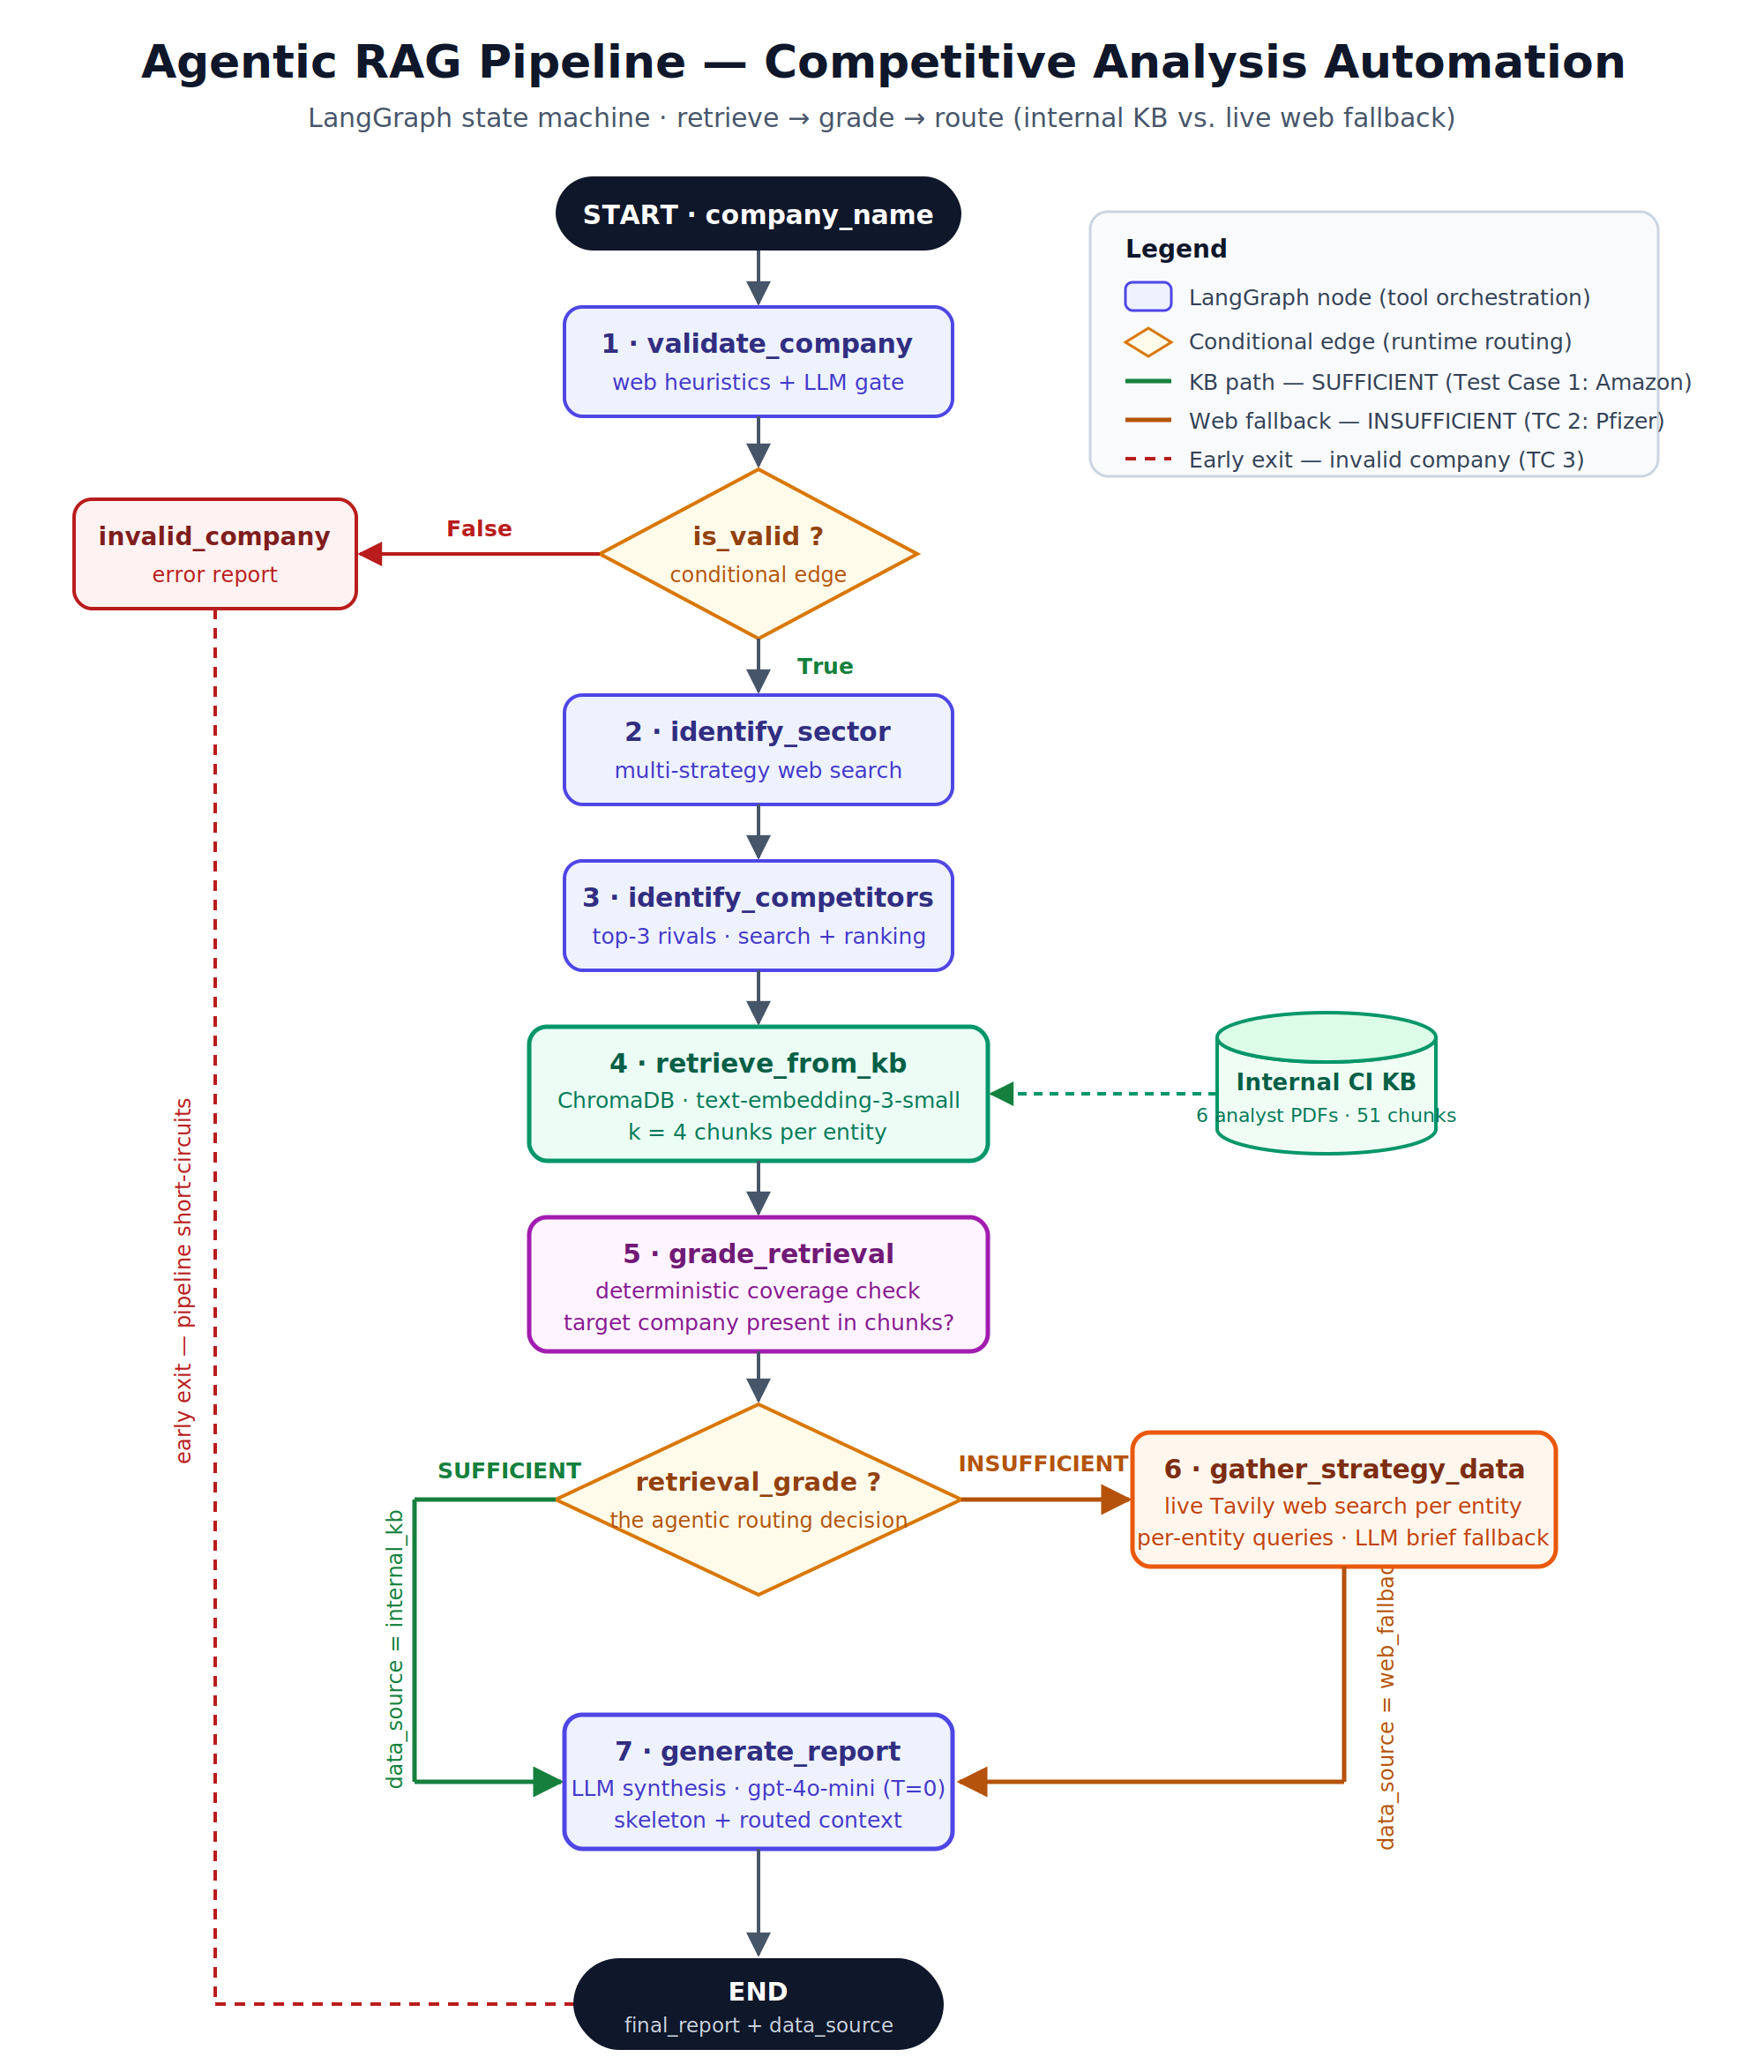


## Setup: Installing and Importing Libraries


### Install Dependencies

Run the cell below to install all required packages. If you are on a clean environment, restart the kernel after installation before continuing.


In [1]:
# %pip install -q \
# openai==1.66.3 \
# langchain==0.3.20 \
# langchain-openai==0.3.9 \
# langchain-community==0.3.19 \
# langchain-chroma==0.2.2 \
# langgraph==0.3.21 \
# chromadb==0.6.3 \
# tavily-python==0.5.0 \
# PyPDF2==3.0.1 \
# --disable-pip-version-check

> **Note:** If you encounter import errors after installation, restart the kernel (Runtime -> Restart kernel) and re-run from the top.


### Import Libraries


In [1]:
import os
import re
import json
import time
import warnings
import PyPDF2
from pathlib import Path
from typing import TypedDict, List

from tavily import TavilyClient

from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_community.vectorstores import Chroma
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langgraph.graph import StateGraph, END

warnings.filterwarnings("ignore")
print("All libraries imported successfully.")

/tmp/ipykernel_3632/2991820979.py:13: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import Chroma


All libraries imported successfully.


## Model Initialization

### Loading API Credentials

Credentials are stored in a local `config.json` file in the working directory. The file must contain:

```json
{
  "openai_api_key": "sk-...",
  "tavily_api_key": "tvly-..."
}
```


In [2]:
# Load API keys from config.json
with open("../../../config.json") as f:
    config = json.load(f)

os.environ["OPENAI_API_KEY"] = config["API_KEY"]
os.environ["OPENAI_BASE_URL"] = config["OPENAI_API_BASE"]
os.environ["TAVILY_API_KEY"] = config["TAVILY_API_KEY"]

print("API credentials loaded successfully.")

API credentials loaded successfully.


### LLM Configuration

We use `gpt-4o-mini` at temperature 0 throughout. Temperature 0 keeps the LLM-backed steps (company validation, sector/competitor fallbacks, report synthesis) reproducible across runs. Note that retrieval grading itself is handled by deterministic Python logic, not the LLM -- see Node 5.


In [3]:
# Single shared LLM instance -- temperature=0
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)
print(f"LLM initialized: {llm.model_name}")

LLM initialized: gpt-4o-mini


### Web Search Tool (Tavily)

Tavily is a search API purpose-built for LLM applications. It returns clean, structured results with title, content snippet, and source URL. This is the fallback tool invoked when the internal KB has insufficient coverage.


In [4]:
def web_search_tool(query: str, max_results: int = 5) -> str:
    """
    Run a Tavily search and return formatted results.
    Retries up to 3 times with 1.5x backoff on failure.
    """
    delay = 1.0
    for attempt in range(3):
        try:
            client = TavilyClient(api_key=config["TAVILY_API_KEY"]) # <-- you need to change to uppercase "TAVILY_API_KEY" in your config if not already
            response = client.search(query=query, max_results=max_results)
            snippets = [
                f"{r.get('title', '')}: {r.get('content', '')} ({r.get('url', '')})"
                for r in response.get("results", [])
            ]
            return "\n".join(snippets) if snippets else "No results found."
        except Exception as e:
            if attempt < 2:
                time.sleep(delay)
                delay *= 1.5
            else:
                return f"Search failed after 3 attempts: {e}"


print("web_search_tool defined (Tavily-backed).")

web_search_tool defined (Tavily-backed).


---

## Competitive Intelligence Knowledge Base

### Loading the Corpus

We build an internal Competitive Intelligence (CI) knowledge base covering **Amazon and its three main technology competitors: Microsoft, Google, and Apple**. The corpus consists of 6 analyst documents modeled on what a real strategy team's internal repository might contain.

**Documents:**

| File                                            | Type                      | Coverage                                |
| ----------------------------------------------- | ------------------------- | --------------------------------------- |
| `amazon_strategic_overview_2024.pdf`            | Analyst Brief             | Amazon strategy, AWS, retail, Prime     |
| `microsoft_competitive_position_2024.pdf`       | Analyst Brief             | Microsoft Azure, Office 365, enterprise |
| `google_market_strategy_2024.pdf`               | Analyst Brief             | Google Search, GCP, YouTube             |
| `apple_brand_product_strategy_2024.pdf`         | Analyst Brief             | Apple hardware, iOS ecosystem, services |
| `tech_sector_competitive_landscape_q4_2024.pdf` | Comparison Memo           | All four companies head-to-head         |
| `cloud_services_market_analysis_2024.pdf`       | Pricing/Positioning Sheet | AWS vs Azure vs GCP                     |

> **Note:** All documents used are synthetic and fabricated for teaching purposes only. All figures, dates, and claims are internally consistent across documents but do not represent real financial data.


### Unzip the Corpus PDFs

The cell below unzips `corpus_pdfs.zip` into a directory called `corpus`, which contains all 6 PDF files. Each document contains realistic strategy analyst content with internally consistent figures.


In [5]:
import zipfile

zip_file_path = "corpus_pdfs.zip"
extraction_path = "corpus"

# Create the extraction directory if it doesn't exist
os.makedirs(extraction_path, exist_ok=True)

with zipfile.ZipFile(zip_file_path, "r") as zip_ref:
    zip_ref.extractall(extraction_path)

print(f"'{zip_file_path}' unzipped to '{extraction_path}' successfully.")

'corpus_pdfs.zip' unzipped to 'corpus' successfully.


---

## Knowledge Base Ingestion

### Loading PDFs and Building the ChromaDB Vector Store

We load each PDF from the `corpus/` directory, chunk the text using a `RecursiveCharacterTextSplitter` (600-character chunks, 80-character overlap), and embed each chunk using OpenAI's `text-embedding-3-small` model. Chunks are stored in a local ChromaDB collection with per-document metadata (`company`, `doc_type`, `source`) that can be used for filtered retrieval.

The resulting vector store is the **internal Competitive Intelligence (CI) knowledge base** -- the first port of call when the pipeline needs strategy data on Amazon and its competitors.


In [6]:
# -- 1. Load PDFs and Extract Text -------------------------------------------
def extract_text_from_pdf(pdf_path):
    text = ""
    with open(pdf_path, "rb") as file:
        reader = PyPDF2.PdfReader(file)
        for page_num in range(len(reader.pages)):
            text += reader.pages[page_num].extract_text() or ""
    return text


all_texts = []
all_metadatas = []
CORPUS_DIR = Path("corpus")

print("Loading text from PDF documents...")
for pdf_file in sorted(os.listdir(CORPUS_DIR)):
    if pdf_file.endswith(".pdf"):
        pdf_path = CORPUS_DIR / pdf_file
        text = extract_text_from_pdf(pdf_path)

        # Improved metadata mapping based on specific files
        fname = pdf_file.lower()
        company = (
            "Multiple"
            if "landscape" in fname or "cloud_services" in fname
            else fname.split("_")[0].capitalize()
        )
        doc_type = (
            "Comparison Memo"
            if "landscape" in fname
            else "Pricing Sheet" if "market_analysis" in fname else "Analyst Brief"
        )

        all_texts.append(text)
        all_metadatas.append(
            {"company": company, "doc_type": doc_type, "source": pdf_file}
        )
        print(f"  + Loaded '{pdf_file}' ({len(text):,} chars)")

# -- 2. Chunking -------------------------------------------------------------
splitter = RecursiveCharacterTextSplitter(chunk_size=600, chunk_overlap=80)
chunked_docs = []
chunked_metas = []

for text, meta in zip(all_texts, all_metadatas):
    chunks = splitter.split_text(text)
    chunked_docs.extend(chunks)
    chunked_metas.extend([meta] * len(chunks))

# -- 3. Initialize embedding model and create a vectorstore ------------------
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

vectorstore = Chroma.from_texts(
    texts=chunked_docs,
    embedding=embeddings,
    metadatas=chunked_metas,
    collection_name="competitive_intel_kb",
)

print(f"\nSuccess: Indexed {vectorstore._collection.count()} chunks in ChromaDB.")

Loading text from PDF documents...
  + Loaded 'amazon_strategic_overview_2024.pdf' (4,739 chars)
  + Loaded 'apple_brand_product_strategy_2024.pdf' (4,315 chars)
  + Loaded 'cloud_services_market_analysis_2024.pdf' (4,382 chars)
  + Loaded 'google_market_strategy_2024.pdf' (4,161 chars)
  + Loaded 'microsoft_competitive_position_2024.pdf' (4,042 chars)
  + Loaded 'tech_sector_competitive_landscape_q4_2024.pdf' (3,957 chars)

Success: Indexed 51 chunks in ChromaDB.


---

## Modular Business Tools

The four functions below are **plain Python functions** — no decorator needed.

They are called **directly** by LangGraph node functions, not passed to an LLM
as callable tools. In LangChain, the `@tool` decorator adds metadata for
LLM-facing tool-calling workflows (e.g., ReAct agents). Here, the LangGraph
nodes are the orchestration layer, so `@tool` would add overhead with no benefit.

> **Rule of thumb**: add `@tool` only when you plan to pass the function into
> an LLM's `tools=[ ]` list. For direct node-level calls inside a LangGraph
> graph, plain functions are correct and preferred.


### Tool 1: Validate Company

Uses a two-stage validation:

1. **Heuristic search check** -- runs a web search and looks for evidence signals (domain name, official website phrasing, business entity terms, Wikipedia/news mentions). Requires >= 2 signals.
2. **LLM gate check** -- separately asks the LLM whether the name is a real organization, as a second opinion.

The LLM gate is the primary decider; the web-signal check is logged as supporting evidence and does not override the LLM verdict.


In [7]:
def is_company_valid_based_on_search(results: str, company_name: str) -> bool:
    """
    Heuristic web-signal check.
    Looks for >= 2 of the following evidence signals in Tavily results:
      - official domain appears (e.g. amazon.com)
      - "official site/website" phrasing
      - company name near the word "company"
      - business-entity keyword (Inc, Ltd, LLC, Corp ...)
      - Wikipedia or major news outlet mentions
    Returns True if 2+ signals found.
    NOTE: this is used as *supporting evidence* -- the LLM gate is the primary
    decider; a missing web signal no longer invalidates a real company.
    """
    name_lower = company_name.lower()
    results_lower = results.lower()
    evidence = 0

    # Signal 1: official domain in results
    domain_variant = name_lower.replace(" ", "").replace(".", "")
    if f"{domain_variant}.com" in results_lower or f"{name_lower}.com" in results_lower:
        evidence += 1

    # Signal 2: "official site/website" phrasing anywhere in results
    if "official site" in results_lower or "official website" in results_lower:
        evidence += 1

    # Signal 3: company name appears near the word "company"
    pattern = rf"{re.escape(name_lower)}.{{0,60}}company|company.{{0,60}}{re.escape(name_lower)}"
    if re.search(pattern, results_lower):
        evidence += 1

    # Signal 4: standard business entity keywords
    biz_terms = ["inc", "corp", "ltd", "llc", "plc", "gmbh", "holdings", "group"]
    if any(t in results_lower for t in biz_terms):
        evidence += 1

    # Signal 5: Wikipedia or reputable news source mentions the company
    if (
        "wikipedia" in results_lower
        or "reuters" in results_lower
        or "bloomberg" in results_lower
    ):
        evidence += 1

    return evidence >= 2


def _llm_company_is_real(company: str) -> bool:
    """
    LLM gate -- primary validator.
    Asks the model whether the name refers to a real organisation that exists
    in the real world. Returns True if the model answers REAL.
    """
    prompt = (
        f"Is '{company}' a real company, organisation, or business entity that exists "
        "in the real world? Answer with exactly one word: REAL or FAKE."
    )
    verdict = llm.invoke(prompt).content.strip().upper()
    return verdict.startswith("REAL")


def validate_company(company_name: str) -> str:
    """
    Two-stage company validation.

    PRIMARY GATE  -- LLM judge (REAL / FAKE verdict)
      The LLM has broad knowledge of real companies and is the authoritative
      source. If it says REAL, the company passes regardless of web-signal availability.

    SUPPORTING EVIDENCE -- Heuristic web check
      Runs a Tavily search and counts evidence signals. Logged for transparency
      but does NOT override the LLM gate. If Tavily is unavailable or returns
      no domain/keyword signals for a valid company, validation still succeeds.

    ROUTING:
      LLM says REAL  -> "[ VALID COMPANY ]..."  -> is_valid = True
      LLM says FAKE  -> "[NOT valid company]..." -> is_valid = False
    """
    # Web search for supporting evidence
    query = f'"{company_name}" company business official site'
    results = web_search_tool(query, max_results=5)
    tool_valid = is_company_valid_based_on_search(results, company_name)

    # LLM gate -- primary decision
    llm_valid = _llm_company_is_real(company_name)

    if llm_valid:
        # LLM confirms real -- web signals are supplementary
        web_note = "web signals: confirmed" if tool_valid else "web signals: limited"
        return f"[ VALID COMPANY ]: {company_name} -- LLM confirmed ({web_note})."
    else:
        # LLM says FAKE -- reject regardless of web signals
        return (
            f"[NOT valid company]: '{company_name}' -- "
            "LLM does not recognise this as a real organisation."
        )


print("validate_company and helpers defined.")

validate_company and helpers defined.


### Tool 2: Identify Sector

Runs three web searches with different query formulations, then extracts sector keywords using weighted pattern matching. Falls back to an LLM classifier if all searches fail.


In [8]:
KNOWN_SECTORS = [
    "Technology",
    "Finance",
    "Healthcare",
    "Education",
    "Retail",
    "Manufacturing",
    "Energy",
    "Telecommunications",
]

SECTOR_KEYWORDS = {
    "Technology": [
        "software",
        "hardware",
        "tech",
        "cloud",
        "saas",
        "platform",
        "digital",
        "ai",
        "semiconductor",
        "internet",
    ],
    "Finance": [
        "bank",
        "insurance",
        "fintech",
        "investment",
        "capital",
        "financial",
        "trading",
        "payments",
        "wealth",
    ],
    "Healthcare": [
        "pharma",
        "biotech",
        "hospital",
        "medical",
        "health",
        "drug",
        "clinical",
        "therapeutics",
        "diagnostics",
    ],
    "Education": [
        "university",
        "edtech",
        "learning",
        "school",
        "training",
        "e-learning",
        "academic",
        "curriculum",
    ],
    "Retail": [
        "retail",
        "ecommerce",
        "store",
        "consumer",
        "merchandise",
        "shopping",
        "fashion",
        "grocery",
    ],
    "Manufacturing": [
        "manufacturing",
        "industrial",
        "factory",
        "automotive",
        "aerospace",
        "chemical",
        "production",
    ],
    "Energy": [
        "energy",
        "oil",
        "gas",
        "renewable",
        "solar",
        "wind",
        "utility",
        "power",
        "petroleum",
    ],
    "Telecommunications": [
        "telecom",
        "wireless",
        "carrier",
        "network",
        "broadband",
        "5g",
        "mobile",
        "isp",
    ],
}


def extract_sectors_advanced(search_results: str, company_name: str) -> list:
    """Score each sector by keyword frequency; double-weight if keyword is near the company name."""
    text = search_results.lower()
    name_lower = company_name.lower()
    scores = {s: 0 for s in KNOWN_SECTORS}

    for sector, keywords in SECTOR_KEYWORDS.items():
        for kw in keywords:
            count = text.count(kw)
            if count:
                scores[sector] += count
                pattern = rf"{re.escape(name_lower)}.{{0,80}}{re.escape(kw)}|{re.escape(kw)}.{{0,80}}{re.escape(name_lower)}"
                if re.search(pattern, text):
                    scores[sector] += count

    return [s for s, v in sorted(scores.items(), key=lambda x: -x[1]) if v > 0]


def llm_classify_sector(company_name: str) -> str:
    """LLM fallback: classify sector from known list."""
    prompt = (
        f"What industry sector does '{company_name}' operate in? "
        f"Choose exactly one from this list: {', '.join(KNOWN_SECTORS)}. "
        "Answer with the sector name only."
    )
    return llm.invoke(prompt).content.strip()


def identify_sector(company_name: str) -> str:
    """Identify the primary industry sector for company_name."""
    queries = [
        f"{company_name} industry sector",
        f"{company_name} wikipedia business type",
        f"{company_name} company sector financial news",
    ]
    combined = ""
    for q in queries:
        combined += web_search_tool(q, max_results=3) + "\n"
        time.sleep(1)

    ranked = extract_sectors_advanced(combined, company_name)
    if ranked:
        return ranked[0]
    return llm_classify_sector(company_name)


print("identify_sector defined.")

identify_sector defined.


### Tool 3: Identify Competitors

Runs three web search queries, extracts company names from the results using regex patterns and a static sector map, ranks candidates by mention frequency, and returns the top 3. Falls back to LLM or the static map if web search returns no usable results.


In [9]:
SECTOR_COMPANIES = {
    "Technology": [
        "Microsoft",
        "Google",
        "Apple",
        "Meta",
        "Amazon",
        "Samsung",
        "IBM",
        "Oracle",
    ],
    "Finance": [
        "JPMorgan Chase",
        "Goldman Sachs",
        "Bank of America",
        "Citigroup",
        "Wells Fargo",
        "BlackRock",
    ],
    "Healthcare": [
        "Johnson & Johnson",
        "Pfizer",
        "Novartis",
        "Roche",
        "AbbVie",
        "Merck",
        "UnitedHealth",
    ],
    "Education": [
        "Coursera",
        "edX",
        "Pearson",
        "2U",
        "Chegg",
        "Duolingo",
        "Khan Academy",
    ],
    "Retail": [
        "Walmart",
        "Target",
        "Costco",
        "Kroger",
        "Home Depot",
        "Alibaba",
        "eBay",
    ],
    "Manufacturing": [
        "Toyota",
        "General Motors",
        "Ford",
        "Siemens",
        "Caterpillar",
        "3M",
        "GE",
    ],
    "Energy": [
        "ExxonMobil",
        "Shell",
        "BP",
        "Chevron",
        "TotalEnergies",
        "NextEra Energy",
    ],
    "Telecommunications": [
        "AT&T",
        "Verizon",
        "T-Mobile",
        "Deutsche Telekom",
        "Comcast",
        "Vodafone",
    ],
}


def is_likely_company_name(text: str) -> bool:
    """Basic filter to reduce noise in extracted competitor candidates."""
    text = text.strip()
    if len(text) < 2 or len(text) > 50:
        return False
    noise = ["the", "and", "for", "with", "that", "this", "from", "company", "inc"]
    if text.lower() in noise:
        return False
    return text[0].isupper()


def extract_competitors_advanced(results: str, exclude: str, sector: str) -> list:
    """Extract competitor candidates from search results."""
    candidates = []
    sector_cos = SECTOR_COMPANIES.get(sector, [])
    results_lower = results.lower()
    for co in sector_cos:
        if co.lower() != exclude.lower() and co.lower() in results_lower:
            candidates.append(co)

    numbered = re.findall(r"\d+\.\s+([A-Z][a-zA-Z\s&\-\.]{1,40})", results)
    candidates.extend(
        [c.strip() for c in numbered if is_likely_company_name(c.strip())]
    )

    comp_match = re.search(
        r"competitors?\s*[:\-]\s*([^.\n]{5,100})", results, re.IGNORECASE
    )
    if comp_match:
        for name in comp_match.group(1).split(","):
            name = name.strip()
            if is_likely_company_name(name):
                candidates.append(name)

    return candidates


def rank_competitors(candidates: list, exclude: str) -> list:
    """Rank candidates by frequency; filter out the target company."""
    counts = {}
    for c in candidates:
        key = c.strip().title()
        if key.lower() != exclude.lower():
            counts[key] = counts.get(key, 0) + 1
    ranked = sorted(counts.items(), key=lambda x: -x[1])
    return [name for name, _ in ranked]


def llm_competitors(company_name: str, sector: str) -> str:
    """LLM fallback for competitor identification."""
    prompt = (
        f"Name the top 3 direct competitors of {company_name} in the {sector} sector. "
        "Return only the company names separated by commas, nothing else."
    )
    return llm.invoke(prompt).content.strip()


def identify_competitors(sector: str, company_name: str) -> str:
    """Discover the top 3 competitors for company_name in sector."""
    queries = [
        f"top {sector} companies competitors market share 2024",
        f"{company_name} direct rivals competitors {sector}",
        f"{sector} industry key players analysis 2024",
    ]
    combined = ""
    for q in queries:
        combined += web_search_tool(q, max_results=4) + "\n"
        time.sleep(1)

    candidates = extract_competitors_advanced(combined, company_name, sector)
    ranked = rank_competitors(candidates, company_name)[:3]

    if len(ranked) >= 3:
        return ", ".join(ranked[:3])

    llm_result = llm_competitors(company_name, sector)
    if llm_result and "," in llm_result:
        return llm_result

    sector_cos = [
        c for c in SECTOR_COMPANIES.get(sector, []) if c.lower() != company_name.lower()
    ]
    return ", ".join(sector_cos[:3]) if sector_cos else "No competitors identified"


print("identify_competitors defined.")

identify_competitors defined.


### Tool 4: Generate Report (Skeleton Builder)

Constructs a deterministic Markdown skeleton for the competitive analysis report -- header, section stubs, and a comparison table with competitor rows. The LLM synthesis node (`generate_report_node`) later fills in the table cells and writes the narrative.


In [10]:
def extract_competitors_from_context(context: str) -> list:
    """Parse a comma-separated competitor string or extract from context phrases."""
    if "," in context and len(context) < 200:
        names = [n.strip() for n in context.split(",") if n.strip()]
        return list(dict.fromkeys(names))[:5]
    match = re.search(
        r"(?:competitors?|top companies)[:\s]+([^\n.]{5,150})", context, re.IGNORECASE
    )
    if match:
        names = [n.strip() for n in match.group(1).split(",") if n.strip()]
        return list(dict.fromkeys(names))[:5]
    return []


def generate_report(company_name: str, context: str) -> str:
    """
    Build a Markdown skeleton for the competitive analysis report.
    The LLM synthesis step will fill in the table rows and narrative.
    """
    competitors = extract_competitors_from_context(context)
    if competitors:
        rows = "\n".join(
            f"| {comp} | [Strategy Type] | [Key Tactics] | [Strengths] | [Weaknesses] |"
            for comp in competitors[:3]
        )
    else:
        rows = (
            "| Competitor 1 | [Strategy Type] | [Key Tactics] | [Strengths] | [Weaknesses] |\n"
            "| Competitor 2 | [Strategy Type] | [Key Tactics] | [Strengths] | [Weaknesses] |\n"
            "| Competitor 3 | [Strategy Type] | [Key Tactics] | [Strengths] | [Weaknesses] |"
        )
    return f"""# Competitive Analysis Report: {company_name}

## Executive Summary
[LLM to fill: 2-3 sentence overview of {company_name}'s competitive position in its sector.]

## Competitor Comparison

| Competitor | Strategy Type | Key Tactics | Strengths | Weaknesses |
|-----------|--------------|-------------|-----------|------------|
{rows}

## Actionable Insights
- [Insight 1: LLM to fill based on gathered context]
- [Insight 2: LLM to fill]
- [Insight 3: LLM to fill]

---
*Report synthesized by LLM from gathered competitive intelligence.*
"""


print("generate_report defined.")

generate_report defined.


---

## LangGraph Agentic Workflow

### Agent State

The `AgentState` TypedDict is the shared working memory of the LangGraph graph. Every node reads from and writes back to this state object.

The Three fields supporting the Agentic RAG:

- `retrieved_chunks` -- raw text chunks fetched from the ChromaDB knowledge base
- `retrieval_grade` -- the LLM grader's verdict: `"SUFFICIENT"` or `"INSUFFICIENT"`
- `data_source` -- which path was taken: `"internal_kb"` or `"web_fallback"`


In [11]:
class AgentState(TypedDict, total=False):
    # -- Input --------------------------------------------------
    company_name: str

    # -- Validation signals -------------------------------------
    validation_result: str
    is_valid: bool

    # -- Industry & competitors ---------------------------------
    sector: str
    competitors: str
    competitor_list: List[str]

    # -- Agentic RAG fields -------------------------------------
    retrieved_chunks: List[str]
    retrieval_grade: str
    data_source: str

    # -- Research & context -------------------------------------
    strategy_data: dict
    gathered_context: str

    # -- Reporting ----------------------------------------------
    final_report: str


print("AgentState defined.")

AgentState defined.


### LangGraph Node Functions

Each node function takes the full `AgentState`, does one unit of work, updates the relevant fields, and returns the state. Nodes are pure functions -- they do not share mutable state outside of the `AgentState` dict.


#### Node 1: Validate Company


In [12]:
def validate_company_node(state: AgentState) -> AgentState:
    """
    NODE 1 -- VALIDATE COMPANY
    --------------------------------------------------------------------------
    PURPOSE : Gate-check the input company name before spending any compute on
              sector identification, competitor discovery, or KB retrieval.

    TWO-STAGE VALIDATION:
      Stage A -- Heuristic web check
                Runs a Tavily search and scans results for >=2 evidence signals:
                official domain, "official site/website" phrasing, business-
                entity keywords (Inc, Ltd, LLC...), Wikipedia/news mentions.
      Stage B -- LLM gate
                Separately asks the LLM "Is this a real organisation?" as an
                independent second opinion (returns REAL or FAKE).
      LLM says REAL -> is_valid = True  (web signals are supplementary).

    STATE READS : company_name
    STATE WRITES: validation_result, is_valid

    ROUTING (conditional edge after this node):
      is_valid = True  -> identify_sector  (pipeline continues)
      is_valid = False -> invalid_company  -> END  (pipeline short-circuits)
    """
    company = state["company_name"]

    # Run full two-stage validation (heuristic search + LLM gate)
    result = validate_company(company)
    state["validation_result"] = result

    # Parse flags from the structured response string for downstream routing
    state["is_valid"] = "[ VALID COMPANY ]" in result

    print(f"[NODE 1 | validate_company]  '{company}' -> is_valid={state['is_valid']}")
    return state


def invalid_company_node(state: AgentState) -> AgentState:
    """
    NODE 1b -- INVALID COMPANY  (early-exit branch)
    --------------------------------------------------------------------------
    PURPOSE : Reached only when validation fails. Writes a human-readable
              error report and exits the graph immediately -- the caller gets a
              meaningful response rather than a crash or empty output.

    STATE WRITES: final_report  (error message explaining the failure)
    NEXT STEP   : END
    """
    # Build a user-friendly error report so the caller understands what happened
    state["final_report"] = (
        f"# Competitive Analysis Report: {state['company_name']}\n\n"
        f"**Status:** Could not validate '{state['company_name']}' as a real company.\n\n"
        f"Validation detail: {state.get('validation_result', 'N/A')}\n\n"
        "Please re-check the company name and try again."
    )
    return state


print("validate_company_node and invalid_company_node defined.")

validate_company_node and invalid_company_node defined.


#### Node 2: Identify Sector


In [13]:
def identify_sector_node(state: AgentState) -> AgentState:
    """
    NODE 2 -- IDENTIFY SECTOR
    --------------------------------------------------------------------------
    PURPOSE : Classify the target company into one of the known industry
              sectors so that competitor search can be scoped correctly.

    HOW IT WORKS:
      Fires 3 Tavily searches with different angles (general industry,
      Wikipedia/LinkedIn-style, financial news), then scores each sector
      by keyword frequency -- double weight when the keyword appears near
      the company name. Falls back to an LLM classifier if searches are
      inconclusive.

    STATE READS : company_name
    STATE WRITES: sector  (e.g. "Technology", "Healthcare", "Finance")

    WHY IT MATTERS:
      The sector drives competitor discovery and is printed in the final
      report. An incorrect sector produces irrelevant competitors and a
      misleading analysis.

    NEXT STEP: identify_competitors
    """
    # classify the company's primary industry using multi-strategy web search
    state["sector"] = identify_sector(state["company_name"])
    print(
        f"[NODE 2 | identify_sector]  '{state['company_name']}' -> sector='{state['sector']}'"
    )
    return state

#### Node 3: Identify Competitors


In [14]:
def identify_competitors_node(state: AgentState) -> AgentState:
    """
    NODE 3 -- IDENTIFY COMPETITORS
    --------------------------------------------------------------------------
    PURPOSE : Discover the top 3 direct rivals so the pipeline knows which
              companies to retrieve KB data for and populate the comparison table.

    HOW IT WORKS:
      Fires 3 Tavily searches (market share, direct rivals, industry analysis),
      cross-references results against a static sector map, and regex-extracts
      named competitors. Candidates are ranked by mention frequency.
      Falls back to LLM or the static sector map when search returns noise.

    STATE READS : company_name, sector
    STATE WRITES:
      competitors     -- comma-separated string  e.g. "Microsoft, Google, Apple"
      competitor_list -- Python list of max 3 names; used by the KB retrieval
                        node to run a separate per-entity similarity search

    NEXT STEP: retrieve_from_kb
    """
    competitors_str = identify_competitors(state["sector"], state["company_name"])
    state["competitors"] = competitors_str

    # Parse into a list (max 3) -- per-entity queries in retrieve_from_kb_node
    state["competitor_list"] = [
        c.strip() for c in competitors_str.split(",") if c.strip()
    ][:3]
    print(f"[NODE 3 | identify_competitors]  -> {state['competitor_list']}")
    return state

#### Node 4: Retrieve from Knowledge Base

This is the first Agentic RAG node. It queries the ChromaDB vector store for the target company and each of its three competitors, collecting the top-4 most semantically similar chunks per entity. All retrieved chunks are stored in `state["retrieved_chunks"]` for the grader.


In [15]:
def retrieve_from_kb_node(state: AgentState) -> AgentState:
    """
    NODE 4 -- RETRIEVE FROM KNOWLEDGE BASE   [Agentic RAG -- Retrieval Stage]
    --------------------------------------------------------------------------
    PURPOSE : Pull the most semantically relevant text chunks from the internal
              Competitive Intelligence KB for every entity in scope (target
              company + all 3 competitors).

    HOW IT WORKS:
      For each entity, ChromaDB runs a cosine-similarity search over the
      embedded corpus (text-embedding-3-small, 600-char chunks, 80-char
      overlap). We fetch k=4 chunks per entity -- enough for the grader to
      assess all required fields without overloading the context window.
      Chunks from all entities are collected into a flat list.

    WHY PER-ENTITY QUERIES:
      A single query on the target company alone would not surface competitor
      chunks (they occupy different embedding regions). Querying each entity
      separately maximises recall across the full scope of the report.

    STATE READS : company_name, competitor_list
    STATE WRITES: retrieved_chunks  -- flat list of raw text strings

    NEXT STEP: grade_retrieval
      The grader will inspect these chunks and decide whether they are
      sufficient (stay on KB path) or require a live web search (fallback).
    """
    entities = [state["company_name"]] + state.get("competitor_list", [])
    all_chunks = []

    for entity in entities:
        # Semantic similarity search -- returns k Document objects ranked by relevance
        results = vectorstore.similarity_search(entity, k=4)
        entity_chunks = [doc.page_content for doc in results]
        all_chunks.extend(entity_chunks)
        print(
            f"  [NODE 4 | retrieve_from_kb]  '{entity}' -> {len(entity_chunks)} chunks"
        )

    state["retrieved_chunks"] = all_chunks
    print(
        f"[NODE 4 | retrieve_from_kb]  Total = {len(all_chunks)} chunks -> forwarding to grader"
    )
    return state

#### Node 5: Grade Retrieval (The Agentic Decision Point)

This node is the heart of the Agentic RAG pattern. It grades the retrieval using a **deterministic, logic-based coverage check**: is the target company explicitly present in the retrieved chunks, and is there enough content to work with? No LLM call is involved in the grading itself.

- **SUFFICIENT** -> the graph routes directly to `generate_report` using the KB data
- **INSUFFICIENT** -> the graph routes to `gather_strategy_data` (live Tavily web search) before generating the report

The _agentic_ element is the **runtime branching decision**: the route is not hardcoded -- it depends entirely on what the grader finds in the retrieved content for the specific company being analyzed.

##### Design choice: logic-based grading vs. LLM-as-grader

An alternative design would ask the LLM itself to judge SUFFICIENT/INSUFFICIENT. Both approaches are used in production systems -- here is the trade-off:

|          | Logic-based grader (used here)                                                                                                                                                                 | LLM-as-grader                                                                                                                                                                                                              |
| -------- | ---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- | -------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **Pros** | Deterministic and fully reproducible -- test cases always route the same way; zero extra cost/latency; trivially easy to unit-test and debug; the decision rule is transparent and explainable | Semantic judgment -- handles paraphrases and name variants ("Alphabet Inc." vs "Google"); can assess _quality_ of coverage (are all report fields answerable?), not just presence; no manual rules to maintain             |
| **Cons** | Brittle to name variants and phrasing it was not written for; no semantic understanding -- checks presence, not usefulness; rules must be extended by hand for new requirements                | Non-deterministic in edge cases and can drift across model versions; may hallucinate sufficiency when chunks contain rich but _wrong-company_ content; adds an LLM call (cost + latency) per run; harder to test and audit |

For this notebook we deliberately keep the grader **simple and logic-based**: it makes every test case reproducible and lets you focus on the routing pattern itself. Upgrading to an LLM (or hybrid) grader is a natural extension -- see Future Scope.


In [16]:
def grade_retrieval_node(state: AgentState) -> AgentState:
    """
    NODE 5 -- GRADE RETRIEVAL   [Agentic RAG -- The Self-Correction Decision Point]
    --------------------------------------------------------------------------
    PURPOSE : Decide at runtime whether the KB chunks contain useful information
              about the TARGET COMPANY specifically -- or whether the pipeline
              must escalate to a live Tavily web search (fallback).

    HOW IT WORKS (deterministic check, not LLM-based):
      The grader checks ONE clear condition: is the target company name explicitly
      present in the retrieved chunks?  If yes -> SUFFICIENT (KB has the data).
      If no -> INSUFFICIENT (KB does not cover this company; use web fallback).

    WHY ONLY THE TARGET COMPANY NAME?
      Competitor names returned by Tavily can vary ("Alphabet Inc." vs "Google",
      "Microsoft Corporation" vs "Microsoft").  Requiring exact competitor name
      matches causes false negatives for valid KB hits -- Amazon failing because
      its competitor was called "Alphabet Inc." instead of "Google".
      The target company is the definitive signal: if our KB covers it, we have
      everything we need (the corpus covers all four tech companies together).

    WHY NOT LLM-BASED GRADING?
      An LLM grader can hallucinate coverage when chunks contain related-but-wrong
      company data (Pfizer query returns Amazon chunks; LLM sees rich strategy
      content and says SUFFICIENT even though it is about a different company).
      A deterministic name-presence check is simpler and more reliable here.

    STATE READS : retrieved_chunks, company_name
    STATE WRITES:
      retrieval_grade -- "SUFFICIENT" or "INSUFFICIENT"
      data_source     -- "internal_kb"  (SUFFICIENT path)
                         "web_fallback" (INSUFFICIENT path)

    ROUTING (conditional edge after this node):
      SUFFICIENT   -> generate_report        (KB data used directly)
      INSUFFICIENT -> gather_strategy_data   (live Tavily search kicks in)
    """
    target = state["company_name"].strip().lower()
    chunks_text = " ".join(state.get("retrieved_chunks", []))
    chunks_lower = chunks_text.lower()

    # Core check: is the target company name present in the retrieved KB chunks?
    name_found = target in chunks_lower

    # Minimum content sanity: at least 5 chunks and 500 chars of text
    content_ok = len(state.get("retrieved_chunks", [])) >= 5 and len(chunks_text) >= 500

    verdict = "SUFFICIENT" if (name_found and content_ok) else "INSUFFICIENT"

    state["retrieval_grade"] = verdict
    state["data_source"] = "internal_kb" if verdict == "SUFFICIENT" else "web_fallback"

    print(
        f"[NODE 5 | grade_retrieval]  target='{state['company_name']}' "
        f"name_in_chunks={name_found}  content_ok={content_ok} "
        f"-> verdict={verdict}  data_source={state['data_source']}"
    )
    return state

#### Node 6: Gather Strategy Data (Web Fallback)

This node is only reached when the grader returns INSUFFICIENT. It runs a Tavily web search for each entity, consolidating the results into `gathered_context`. The `data_source` flag has already been set to `"web_fallback"` by the grader.


In [17]:
def llm_strategy_brief(entity: str, sector: str) -> str:
    """
    HELPER -- LLM STRATEGY BRIEF
    Generates a concise strategy summary via the LLM when Tavily returns empty
    results. Acts as a last-resort fallback so the pipeline never stalls due to
    transient search failures.
    """
    prompt = (
        f"Provide a brief competitive overview of {entity} in the {sector} sector. "
        "Cover: strategy type, key tactics, main strengths, and main weaknesses. "
        "Keep the response under 300 words."
    )
    return llm.invoke(prompt).content.strip()


def gather_strategy_data_node(state: AgentState) -> AgentState:
    """
    NODE 6 -- GATHER STRATEGY DATA   [Web Fallback -- reached only when KB is INSUFFICIENT]
    --------------------------------------------------------------------------
    PURPOSE : Retrieve live competitive intelligence via Tavily web search for
              every entity when the internal KB does not have sufficient coverage
              (e.g. a company or sector not present in the corpus).

    HOW IT WORKS:
      Loops over every entity (target + competitors) and fires one focused
      Tavily query per entity that asks for strategy, tactics, and
      strengths/weaknesses in a single request -- no fragmented sub-queries.
      A 1-second delay between entities avoids rate-limit errors.
      If Tavily fails for any entity, llm_strategy_brief() generates a
      concise brief from model knowledge so context is never left blank.
      All per-entity results are consolidated into gathered_context.

    STATE READS : company_name, competitor_list, sector, competitors
    STATE WRITES:
      strategy_data    -- dict mapping entity -> raw search text
      gathered_context -- single consolidated string fed to generate_report

    NEXT STEP: generate_report  (same terminal node as the KB path)
    """
    entities = [state["company_name"]] + state.get("competitor_list", [])
    strategy_data = {}

    for entity in entities:
        # Single end-to-end query: strategy + tactics + strengths/weaknesses in one shot
        query = (
            f"{entity} competitive strategy, key business tactics, "
            f"core strengths and weaknesses in the {state.get('sector', '')} sector 2024"
        )
        data = web_search_tool(query, max_results=5)

        # Last resort: LLM brief if Tavily failed or returned nothing useful
        if not data or "failed" in data.lower():
            data = llm_strategy_brief(entity, state.get("sector", ""))

        strategy_data[entity] = data
        print(f"  [NODE 6 | gather_strategy_data]  '{entity}' -> {len(data)} chars")
        time.sleep(1)  # polite rate-limiting between search requests

    state["strategy_data"] = strategy_data

    # Consolidate all entity data into one context block for generate_report_node
    parts = [f"Sector: {state['sector']}", f"Competitors: {state['competitors']}"]
    for entity, data in strategy_data.items():
        parts.append(f"\n## {entity}\n{data[:1500]}")
    state["gathered_context"] = "\n".join(parts)

    print(
        f"[NODE 6 | gather_strategy_data]  Context ready: {len(state['gathered_context'])} chars"
    )
    return state

#### Node 7: Generate Report

The final synthesis node. It selects the appropriate context based on `data_source`:

- If `"internal_kb"`: concatenates the retrieved KB chunks
- If `"web_fallback"`: uses the consolidated web search context

It then builds a Markdown skeleton via `generate_report()` and passes both skeleton + context to the LLM for final synthesis. The report explicitly states which data source was used.


In [18]:
def generate_report_node(state: AgentState) -> AgentState:
    """
    NODE 7 -- GENERATE REPORT   [Final Synthesis -- both KB and web paths converge here]
    --------------------------------------------------------------------------
    PURPOSE : Synthesize a structured Competitive Analysis Report from whichever
              context source was routed by the grader. The report explicitly
              declares its data source for full transparency.

    HOW IT WORKS -- THREE STEPS:

      Step 1 -- Context selection
        data_source = "internal_kb"   -> join retrieved_chunks as LLM context
        data_source = "web_fallback"  -> use gathered_context from Tavily

      Step 2 -- Build Markdown skeleton
        generate_report() creates a template with section headers and an empty
        comparison table -- giving the LLM a rigid output structure to follow.

      Step 3 -- LLM synthesis
        The LLM receives skeleton + selected context and fills in:
          - Executive Summary   (2-3 sentences on competitive position)
          - Competitor Comparison table  (Strategy / Tactics / Strengths / Weaknesses)
          - 3 Actionable Insights  (grounded in the context data)
          - Data source footer  (transparency for the reader)
        Any field without context evidence is marked "Not available from context"
        to prevent hallucination.

    STATE READS : data_source, retrieved_chunks OR gathered_context,
                  company_name, sector, competitors
    STATE WRITES:
      final_report    -- the completed, LLM-synthesized Markdown report

    NEXT STEP: END
    """
    # -- Step 1: Select context based on the route the grader chose -----------
    if state.get("data_source") == "internal_kb":
        # KB path: stitch retrieved chunks into a single reference block
        context = "\n\n".join(state.get("retrieved_chunks", []))
        source_note = (
            "**Data Source:** Internal Competitive Intelligence Knowledge Base"
        )
    else:
        # Web fallback path: use the Tavily-sourced consolidated context
        context = state.get("gathered_context", "No context available.")
        source_note = (
            "**Data Source:** Live Web Search (Tavily) -- KB coverage was insufficient"
        )

    # -- Step 2: Build a deterministic Markdown skeleton ----------------------
    skeleton = generate_report(state["company_name"], state["competitors"])

    # -- Step 3: LLM fills in the skeleton using only the selected context -----
    synthesis_prompt = (
        "You are an expert Competitive Analysis Agent.\n\n"
        f"COMPANY UNDER ANALYSIS: {state['company_name']}\n"
        f"SECTOR: {state['sector']}\n"
        f"TOP COMPETITORS: {state['competitors']}\n"
        f"{source_note}\n\n"
        "REPORT SKELETON (fill in all [placeholder] fields):\n"
        f"{skeleton}\n\n"
        "GATHERED CONTEXT (use ONLY this data -- do not hallucinate):\n"
        f"{context[:5000]}\n\n"
        "INSTRUCTIONS:\n"
        f"1. Fill in the Executive Summary with 2-3 sentences on {state['company_name']}'s competitive position.\n"
        "2. Complete the Competitor Comparison table -- one row per competitor, all 4 fields.\n"
        "3. Write 3 specific, actionable Insights grounded in the context.\n"
        f'4. Add a one-line footer: "{source_note}"\n'
        "5. Mark any field where context is missing as 'Not available from context.'\n\n"
        "OUTPUT FORMAT: Pure Markdown, no preamble."
    )

    state["final_report"] = llm.invoke(synthesis_prompt).content.strip()
    print(
        f"[NODE 7 | generate_report]  Done -- {len(state['final_report'])} chars | source={state.get('data_source')}"
    )
    return state

---

## Build the LangGraph Workflow

Now we wire all nodes together into a `StateGraph`. The graph has **two conditional branches**:

1. **Validation branch** (existing): invalid company -> early-exit `END`
2. **RAG routing branch** (new): grader verdict SUFFICIENT -> `generate_report`; INSUFFICIENT -> `gather_strategy_data` -> `generate_report`


In [ ]:
# -- Build the state graph -----------------------------------------------------
graph = StateGraph(AgentState)

# Register all nodes
graph.add_node("validate_company", validate_company_node)
graph.add_node("invalid_company", invalid_company_node)
graph.add_node("identify_sector", identify_sector_node)
graph.add_node("identify_competitors", identify_competitors_node)
graph.add_node("retrieve_from_kb", retrieve_from_kb_node)
graph.add_node("grade_retrieval", grade_retrieval_node)
graph.add_node("gather_strategy_data", gather_strategy_data_node)
graph.add_node("generate_report", generate_report_node)

# Entry point
graph.set_entry_point("validate_company")

# -- Branch 1: Validation gate -------------------------------------------------
graph.add_conditional_edges(
    "validate_company",
    lambda state: "valid" if state.get("is_valid") else "invalid",
    {
        "valid": "identify_sector",
        "invalid": "invalid_company",
    },
)

# -- Linear pipeline edges -----------------------------------------------------
graph.add_edge("identify_sector", "identify_competitors")
graph.add_edge("identify_competitors", "retrieve_from_kb")
graph.add_edge("retrieve_from_kb", "grade_retrieval")


# -- Branch 2: Agentic RAG routing gate ---------------------------------------
def route_after_grading(state: AgentState) -> str:
    """Conditional routing: KB sufficient -> generate_report; else -> web fallback."""
    return (
        "sufficient" if state.get("retrieval_grade") == "SUFFICIENT" else "insufficient"
    )


graph.add_conditional_edges(
    "grade_retrieval",
    route_after_grading,
    {
        "sufficient": "generate_report",
        "insufficient": "gather_strategy_data",
    },
)

# Web fallback flows into the same report node
graph.add_edge("gather_strategy_data", "generate_report")

# Terminal edges
graph.add_edge("generate_report", END)
graph.add_edge("invalid_company", END)

# Compile
app = graph.compile()
print("LangGraph workflow compiled successfully.")

LangGraph workflow compiled successfully.


### Visualize the Workflow

The Mermaid diagram below shows the complete graph. Notice the two conditional branches: the validation gate at the top and the Agentic RAG routing gate in the middle.


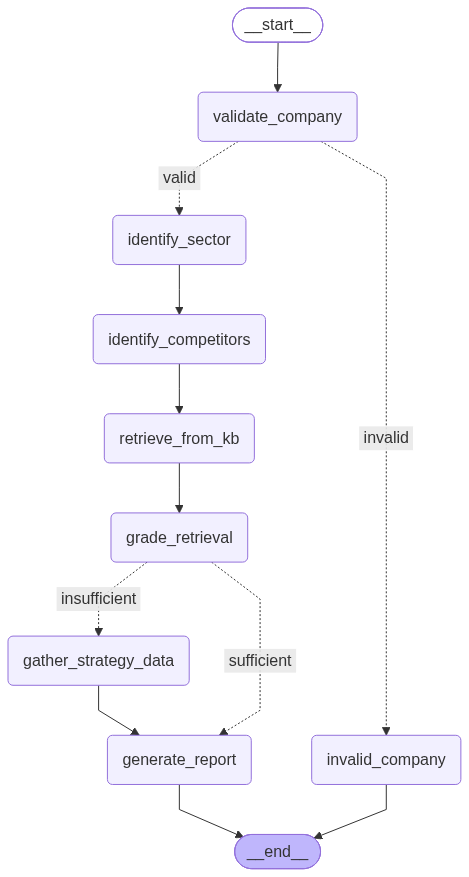

In [20]:
from IPython.display import Image, Markdown, display

try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception:
    # Fallback: print the Mermaid source if graphviz is not available
    print(app.get_graph().draw_mermaid())

---

## Test Cases

Three end-to-end runs exercise every branch of the graph:

| #   | Company              | KB Coverage                 | Expected Route          | Expected `data_source` |
| --- | -------------------- | --------------------------- | ----------------------- | ---------------------- |
| 1   | **Amazon**           | Full coverage (in corpus)   | KB -> `generate_report` | `"internal_kb"`        |
| 2   | **Pfizer**           | No coverage (not in corpus) | KB miss -> web fallback | `"web_fallback"`       |
| 3   | **Zzqxytron Fakeco** | N/A -- invalid name         | Early exit before KB    | N/A                    |

Each test case cell below is a single, self-contained run: it invokes the graph,
prints a pipeline summary (sector, competitors, KB grade, data source, route taken),
and renders the final report -- all in one shot.


### Test Case 1 -- KB Hit: Amazon

Amazon is fully represented in the synthetic corpus (all 6 documents contain
Amazon data). The retrieval grader should return **SUFFICIENT** and the report
should be generated entirely from the internal knowledge base -- no web search needed.


In [21]:
# ===================================================================
# TEST CASE 1 -- Amazon  |  Expected: KB path (SUFFICIENT)
#   Graph route:  validate -> sector -> competitors
#                 -> retrieve_from_kb -> grade (SUFFICIENT)
#                 -> generate_report -> END
# ===================================================================

output_1 = app.invoke({"company_name": "Amazon"})

# Derive actual route from state, not from a hardcoded string
_ds1 = output_1.get("data_source")
if _ds1 == "internal_kb":
    _route1 = "KB SUFFICIENT -> generate_report  (no web search)"
elif _ds1 == "web_fallback":
    _route1 = "KB INSUFFICIENT -> gather_strategy_data (Tavily) -> generate_report"
else:
    _route1 = "early exit (is_valid=False)"

# -- Pipeline summary ---------------------------------------------------------
print("=" * 62)
print(f"  Company          : {output_1.get('company_name')}")
print(f"  Valid            : {output_1.get('is_valid')}")
print(f"  Sector           : {output_1.get('sector')}")
print(f"  Competitors      : {output_1.get('competitors')}")
print(f"  KB Chunks Fetched: {len(output_1.get('retrieved_chunks', []))}")
print(f"  Retrieval Grade  : {output_1.get('retrieval_grade')}")
print(f"  Data Source      : {_ds1}")
print(f"  Route Taken      : {_route1}")
print("=" * 62)

# -- Final Report -------------------------------------------------------------
display(Markdown(output_1["final_report"]))

[NODE 1 | validate_company]  'Amazon' -> is_valid=True
[NODE 2 | identify_sector]  'Amazon' -> sector='Technology'
[NODE 3 | identify_competitors]  -> ['Transsion Holdings', 'Samsung\n\nMarket Share From Q', 'This Comeback Was Driven By Strong Sales']
  [NODE 4 | retrieve_from_kb]  'Amazon' -> 4 chunks
  [NODE 4 | retrieve_from_kb]  'Transsion Holdings' -> 4 chunks
  [NODE 4 | retrieve_from_kb]  'Samsung

Market Share From Q' -> 4 chunks
  [NODE 4 | retrieve_from_kb]  'This Comeback Was Driven By Strong Sales' -> 4 chunks
[NODE 4 | retrieve_from_kb]  Total = 16 chunks -> forwarding to grader
[NODE 5 | grade_retrieval]  target='Amazon' name_in_chunks=True  content_ok=True -> verdict=SUFFICIENT  data_source=internal_kb
[NODE 7 | generate_report]  Done -- 2263 chars | source=internal_kb
  Company          : Amazon
  Valid            : True
  Sector           : Technology
  Competitors      : Transsion Holdings, Samsung

Market Share From Q, This Comeback Was Driven By Strong Sales
  KB Ch

# Competitive Analysis Report: Amazon

## Executive Summary
Amazon.com, Inc. maintains a strong competitive position in the technology sector, driven by its dominance in e-commerce, leading cloud services through AWS, and a robust advertising network. With a diverse revenue stream and a vast logistics infrastructure, Amazon continues to innovate and expand its market share, despite facing regulatory scrutiny and thin margins in retail.

## Competitor Comparison

| Competitor           | Strategy Type                       | Key Tactics                                                                 | Strengths                                                                 | Weaknesses                                                      |
|---------------------|-------------------------------------|-----------------------------------------------------------------------------|---------------------------------------------------------------------------|----------------------------------------------------------------|
| Transsion Holdings   | Not available from context.         | Not available from context.                                               | Not available from context.                                             | Not available from context.                                    |
| Samsung              | Not available from context.         | Not available from context.                                               | Not available from context.                                             | Not available from context.                                    |

## Actionable Insights
- Amazon should continue to leverage its unmatched logistics infrastructure to enhance delivery speed and reliability, further solidifying customer loyalty and Prime membership renewals.
- To mitigate regulatory scrutiny, Amazon could proactively enhance transparency in its marketplace practices and improve third-party seller trust through better quality control measures.
- Expanding the advertising network by utilizing first-party purchase intent data can create additional revenue streams, allowing Amazon to maintain its competitive edge against rivals like Google and Meta.

---
**Data Source:** Internal Competitive Intelligence Knowledge Base

### Test Case 2 -- KB Miss -> Web Fallback: Pfizer

Pfizer is a Healthcare company **not present in the corpus** (which covers
Technology sector only). The grader will return **INSUFFICIENT** because the
retrieved chunks are about Amazon/Microsoft/Google/Apple -- irrelevant for Pfizer.
The graph self-corrects by routing to the Tavily web search fallback.

> This is not a failure -- it is the intended agentic behaviour. The system
> recognises its KB gap and escalates to live search rather than hallucinating.


In [22]:
# ===================================================================
# TEST CASE 2 -- Pfizer  |  Expected: KB miss -> web fallback (INSUFFICIENT)
#   Graph route:  validate -> sector -> competitors
#                 -> retrieve_from_kb -> grade (INSUFFICIENT)
#                 -> gather_strategy_data (Tavily) -> generate_report -> END
# ===================================================================

output_2 = app.invoke({"company_name": "Pfizer"})

# Derive actual route from state, not from a hardcoded string
_ds2 = output_2.get("data_source")
if _ds2 == "internal_kb":
    _route2 = "KB SUFFICIENT -> generate_report  (no web search)"
elif _ds2 == "web_fallback":
    _route2 = "KB INSUFFICIENT -> gather_strategy_data (Tavily) -> generate_report"
else:
    _route2 = "early exit (is_valid=False)"

# -- Pipeline summary ---------------------------------------------------------
print("=" * 62)
print(f"  Company          : {output_2.get('company_name')}")
print(f"  Valid            : {output_2.get('is_valid')}")
print(f"  Sector           : {output_2.get('sector')}")
print(f"  Competitors      : {output_2.get('competitors')}")
print(f"  KB Chunks Fetched: {len(output_2.get('retrieved_chunks', []))}")
print(f"  Retrieval Grade  : {output_2.get('retrieval_grade')}")
print(f"  Data Source      : {_ds2}")
print(f"  Route Taken      : {_route2}")
print("=" * 62)

# -- Final Report -------------------------------------------------------------
display(Markdown(output_2["final_report"]))

[NODE 1 | validate_company]  'Pfizer' -> is_valid=True
[NODE 2 | identify_sector]  'Pfizer' -> sector='Healthcare'
[NODE 3 | identify_competitors]  -> ['In', 'Johnson & Johnson', 'Novartis']
  [NODE 4 | retrieve_from_kb]  'Pfizer' -> 4 chunks
  [NODE 4 | retrieve_from_kb]  'In' -> 4 chunks
  [NODE 4 | retrieve_from_kb]  'Johnson & Johnson' -> 4 chunks
  [NODE 4 | retrieve_from_kb]  'Novartis' -> 4 chunks
[NODE 4 | retrieve_from_kb]  Total = 16 chunks -> forwarding to grader
[NODE 5 | grade_retrieval]  target='Pfizer' name_in_chunks=False  content_ok=True -> verdict=INSUFFICIENT  data_source=web_fallback
  [NODE 6 | gather_strategy_data]  'Pfizer' -> 7482 chars
  [NODE 6 | gather_strategy_data]  'In' -> 6034 chars
  [NODE 6 | gather_strategy_data]  'Johnson & Johnson' -> 6632 chars
  [NODE 6 | gather_strategy_data]  'Novartis' -> 6324 chars
[NODE 6 | gather_strategy_data]  Context ready: 6120 chars
[NODE 7 | generate_report]  Done -- 2491 chars | source=web_fallback
  Company          :

# Competitive Analysis Report: Pfizer

## Executive Summary
Pfizer is navigating a post-pandemic landscape marked by a significant decline in COVID-related revenues while focusing on restoring its earnings power through strategic acquisitions and a diversified product portfolio. The company's emphasis on innovative therapies, particularly in oncology and other growth areas, positions it competitively against major players in the healthcare sector.

## Competitor Comparison

| Competitor         | Strategy Type          | Key Tactics                                                                 | Strengths                                                                 | Weaknesses                                                                 |
|--------------------|-----------------------|-----------------------------------------------------------------------------|---------------------------------------------------------------------------|----------------------------------------------------------------------------|
| In                 | Not available from context | Not available from context                                                  | Not available from context                                                | Not available from context                                                  |
| Johnson & Johnson   | Diversification        | Focus on key therapeutic areas, acquisitions to enhance capabilities       | Strong pharmaceutical division, diverse product portfolio                 | Regulatory and pricing pressures, global economic instability               |
| Novartis           | Streamlined Operations | Creation of Strategy & Growth function, focused decision-making            | Enhanced organizational efficiency, clear therapeutic area focus          | Not available from context                                                  |

## Actionable Insights
- Pfizer should continue to invest in its oncology portfolio and leverage the Seagen acquisition to enhance its competitive edge in this high-growth area.
- Monitoring regulatory changes and pricing pressures faced by competitors like Johnson & Johnson can provide insights for Pfizer to navigate similar challenges effectively.
- Exploring partnerships or collaborations in emerging therapeutic areas could help Pfizer diversify its offerings and mitigate risks associated with declining COVID product sales.

---
**Data Source:** Live Web Search (Tavily) -- KB coverage was insufficient

### Test Case 3 -- Invalid Company: Zzqxytron Fakeco

A clearly fictitious name. The validation node sets `is_valid=False` and the
graph short-circuits to `invalid_company -> END`, never reaching the KB,
the grader, or any search tool.


In [23]:
# ===================================================================
# TEST CASE 3 -- Invalid Company  |  Expected: early exit (is_valid=False)
#   Graph route:  validate -> invalid_company -> END
#   (identify_sector, retrieve_from_kb, grade_retrieval never run)
# ===================================================================

output_3 = app.invoke({"company_name": "Zzqxytron Fakeco"})

# -- Pipeline summary ---------------------------------------------------------
print("=" * 62)
print(f"  Company          : {output_3.get('company_name')}")
print(f"  Valid            : {output_3.get('is_valid')}")
print(f"  Validation Detail: {output_3.get('validation_result', 'N/A')}")
print(f"  Route Taken      : invalid_company -> END  (pipeline short-circuited)")
print("=" * 62)

# -- Error Report -------------------------------------------------------------
display(Markdown(output_3["final_report"]))

[NODE 1 | validate_company]  'Zzqxytron Fakeco' -> is_valid=False
  Company          : Zzqxytron Fakeco
  Valid            : False
  Validation Detail: [NOT valid company]: 'Zzqxytron Fakeco' -- LLM does not recognise this as a real organisation.
  Route Taken      : invalid_company -> END  (pipeline short-circuited)


# Competitive Analysis Report: Zzqxytron Fakeco

**Status:** Could not validate 'Zzqxytron Fakeco' as a real company.

Validation detail: [NOT valid company]: 'Zzqxytron Fakeco' -- LLM does not recognise this as a real organisation.

Please re-check the company name and try again.

In [24]:
# ===================================================================
# TEST CASE 1 -- Amazon  |  Expected: KB path (SUFFICIENT)
#   Graph route:  validate -> sector -> competitors
#                 -> retrieve_from_kb -> grade (SUFFICIENT)
#                 -> generate_report -> END
# ===================================================================

output_1 = app.invoke({"company_name": "Great Learning"})

# Derive actual route from state, not from a hardcoded string
_ds1 = output_1.get("data_source")
if _ds1 == "internal_kb":
    _route1 = "KB SUFFICIENT -> generate_report  (no web search)"
elif _ds1 == "web_fallback":
    _route1 = "KB INSUFFICIENT -> gather_strategy_data (Tavily) -> generate_report"
else:
    _route1 = "early exit (is_valid=False)"

# -- Pipeline summary ---------------------------------------------------------
print("=" * 62)
print(f"  Company          : {output_1.get('company_name')}")
print(f"  Valid            : {output_1.get('is_valid')}")
print(f"  Sector           : {output_1.get('sector')}")
print(f"  Competitors      : {output_1.get('competitors')}")
print(f"  KB Chunks Fetched: {len(output_1.get('retrieved_chunks', []))}")
print(f"  Retrieval Grade  : {output_1.get('retrieval_grade')}")
print(f"  Data Source      : {_ds1}")
print(f"  Route Taken      : {_route1}")
print("=" * 62)

# -- Final Report -------------------------------------------------------------
display(Markdown(output_1["final_report"]))

[NODE 1 | validate_company]  'Great Learning' -> is_valid=True
[NODE 2 | identify_sector]  'Great Learning' -> sector='Education'
[NODE 3 | identify_competitors]  -> ['Coursera', 'Edx', 'Chegg']
  [NODE 4 | retrieve_from_kb]  'Great Learning' -> 4 chunks
  [NODE 4 | retrieve_from_kb]  'Coursera' -> 4 chunks
  [NODE 4 | retrieve_from_kb]  'Edx' -> 4 chunks
  [NODE 4 | retrieve_from_kb]  'Chegg' -> 4 chunks
[NODE 4 | retrieve_from_kb]  Total = 16 chunks -> forwarding to grader
[NODE 5 | grade_retrieval]  target='Great Learning' name_in_chunks=False  content_ok=True -> verdict=INSUFFICIENT  data_source=web_fallback
  [NODE 6 | gather_strategy_data]  'Great Learning' -> 7226 chars
  [NODE 6 | gather_strategy_data]  'Coursera' -> 6919 chars
  [NODE 6 | gather_strategy_data]  'Edx' -> 4810 chars
  [NODE 6 | gather_strategy_data]  'Chegg' -> 6485 chars
[NODE 6 | gather_strategy_data]  Context ready: 6105 chars
[NODE 7 | generate_report]  Done -- 2082 chars | source=web_fallback
  Company     

# Competitive Analysis Report: Great Learning

## Executive Summary
Great Learning is positioned as a key player in the education sector, focusing on personalized learning experiences and the integration of artificial intelligence. With a strategic emphasis on developing both technical and soft skills, Great Learning aims to address the evolving needs of learners and organizations in a competitive landscape.

## Competitor Comparison

| Competitor | Strategy Type | Key Tactics | Strengths | Weaknesses |
|-----------|--------------|-------------|-----------|------------|
| Coursera | Not available from context | Offers a wide range of business strategy courses, including practical case studies and frameworks like SWOT analysis and Porter's Five Forces. | Strong brand recognition, extensive course offerings, partnerships with top universities. | High competition and potential course saturation. |
| Edx | Not available from context | Provides business strategy courses with a focus on competitive analysis, market segmentation, and agile leadership. | Collaboration with prestigious institutions, diverse learning paths. | Limited brand awareness compared to Coursera. |
| Chegg | Not available from context | Focuses on providing educational resources and support, including tutoring and textbook rentals. | Strong presence in student support services, growing demand for online education. | Declining revenues and increasing operational costs. |

## Actionable Insights
- Great Learning should enhance its marketing strategies to highlight its unique offerings in personalized learning and AI integration, differentiating itself from competitors like Coursera and Edx.
- Investing in collaborative learning approaches could improve employee engagement and knowledge retention, addressing the challenges of measuring training effectiveness.
- Monitoring competitors' course offerings and adapting to emerging trends in the education sector will be crucial for maintaining a competitive edge.

---
**Data Source:** Live Web Search (Tavily) -- KB coverage was insufficient

---

## Conclusion

### What We Built

This notebook demonstrates a complete **Agentic RAG pipeline** for Competitive Analysis Automation, implemented as a LangGraph state machine with the following capabilities:

| Capability                    | Implementation                                                   |
| ----------------------------- | ---------------------------------------------------------------- |
| Company validation            | Two-stage: web heuristics + LLM gate                             |
| Sector & competitor discovery | Multi-strategy web search + LLM fallback                         |
| Internal KB retrieval         | ChromaDB + `text-embedding-3-small` semantic search              |
| Retrieval grading             | Deterministic Python coverage check -- SUFFICIENT / INSUFFICIENT |
| Agentic source routing        | LangGraph conditional edge based on grader verdict               |
| Web fallback                  | Tavily live search when KB coverage is insufficient              |
| Report synthesis              | LLM fills skeleton from whichever context was routed             |

### Key Agentic RAG Concept

The critical insight is the **runtime source-selection decision**: rather than always fetching live data (expensive, latency-heavy, may be incomplete) or always using the KB (stale if company not in corpus), the agent _grades its own retrieval_ and decides which source to trust. This self-correcting loop is what makes the pattern _agentic_.

### Future Scope

1. **Multi-hop retrieval**: if the first retrieval is INSUFFICIENT, retrieve additional chunks with a refined query before falling back to web -- reducing unnecessary web calls.
2. **KB refresh pipeline**: automate ingestion of new analyst reports on a schedule, keeping the KB current without manual intervention.
3. **Hybrid retrieval**: combine KB chunks + targeted web searches even when the KB is SUFFICIENT, for maximum coverage.
4. **Source attribution**: add chunk metadata (document title, section, date) to the final report for auditability.
5. **LLM-based or hybrid grading**: augment the deterministic coverage check with an LLM judge (temperature 0) that assesses whether all report fields are answerable from the chunks -- gaining semantic flexibility at the cost of determinism, latency, and testability (see the Pros/Cons comparison in Node 5).
6. **Streaming output**: use LangGraph's streaming API to display the report as it is generated token-by-token.
